# Smart Microscopy v3.1 — Adaptive Target Acquisition

Acquire an overview scan at the source objective, segment cells, pick targets from the cell distribution, then re-acquire those targets at the target objective.

## Workflow

| Step | What it does | Before you run it |
|------|--------------|-------------------|
| 1. Initialization | Connect, validate, boot the engine | Connect LAS X |
| 2a. Define limits | Derive XY stage limits | Place boundary markers |
| 2b. Define positions | Read the scan-field tiles | Draw the scan field |
| 2c. Define focus map | Fit a z-wide focus surface | Place focus markers |
| 3. Acquire overview | Scan and segment every tile | — |
| 4. Target discovery | Pick targets from the distribution | — |
| 5. Target acquisition | Re-acquire targets at high magnification | — |
| 6. Finish | Write the summary, plot, shut down | — |

All workflow logic lives in `notebooks/workflow/`; this notebook is a thin wrapper. See `docs/TARGET_ACQUISITION_DESIGN.md` for the design.

## Configuration

Edit the cell below for your experiment, then run the steps in order.

`simulate=True` is a **simulator-only dry run**: every saved `.ome.tiff` from Step 3 and Step 5 has its pixels swapped for mock content (`mock_image_source` picks the source) under the original LAS X simulator's OME envelope, so the rest of the pipeline behaves identically to a real acquisition. A per-frame `SystemTypeName="SIMULATOR"` guard hard-aborts the run if any frame is not from the simulator — `simulate=True` cannot touch real-instrument data.

**Before a real run:** set `simulate=False`, check each job's objective in LAS X, and set the z-galvo to 0.

In [2]:
from _workflow_bootstrap import Config, Path

cfg = Config(
    # Jobs (each has an objective configured in LAS X)
    acquisition_job="Overview",
    target_job="HiRes",
    af_job="AF Job",

    # Paths
    analysis_repo=Path(r"Z:\zmbstaff\10374\Protocols_Notes\thom\notes\repositories\smart-analysis"),
    experiment="v3-test",   # driver derives output_root as media_path/smart

    # Simulator dry run (LAS X simulator only). When True, every saved
    # .ome.tiff from Step 3 / Step 5 has its pixels overwritten with
    # mock content; the OME envelope, naming, layout, and analysis flow
    # are otherwise unchanged. The per-frame SystemTypeName=="SIMULATOR"
    # guard makes this unsafe to enable on real hardware -- the run
    # hard-aborts on the first non-simulator frame.
    simulate=False,
    mock_image_source=None,
    # simulate=True,
    # mock_image_source="skimage_human_mitosis",
)

## Step 1 — Initialization

Connects to LAS X, validates hardware and calibration, derives objective slots, and boots the analysis engine.

**Before running:** connect LAS X.

In [3]:
from workflow import connect_lasx, preflight

client = connect_lasx()
ctx = preflight(cfg, client)


[job] 'Overview' selected (slot 1)
[step 1] preflight ok
  templates_dir : C:\Users\t.de\AppData\Roaming\Leica Microsystems\LAS X\MatrixScreener6\User_0\ScanningTemplates
  out_dir       : E:\smart\v3-test_076rgj
  current_job   : Overview  (slot 1)
  target_job    : HiRes  (slot 2)
  source z-galvo: -0.000 um
  cellpose env  : present


## Step 2 — Setup overview

Configure the overview scan's spatial extent. Run 2a → 2b → 2c in order.

### Step 2a — Define limits

Derives XY stage limits from boundary markers (or uses the physical envelope if none are placed) and forces every job to z-wide.

**Before running:** place point markers at the sample corners in Navigator Expert, or skip to use the physical envelope.

[step 2a] Stage limits from 4 boundary marker(s) (envelope from stage.json):
  X: 27151 - 36423 um
  Y: 14612 - 23797 um
  z-wide: 0 - 25000 um (from stage.json)
[step 2a] Template stripped and z-wide enforced on every job.
[step 2a] Saved E:\smart\v3-test_076rgj\initialization\logs\stage_envelope.png


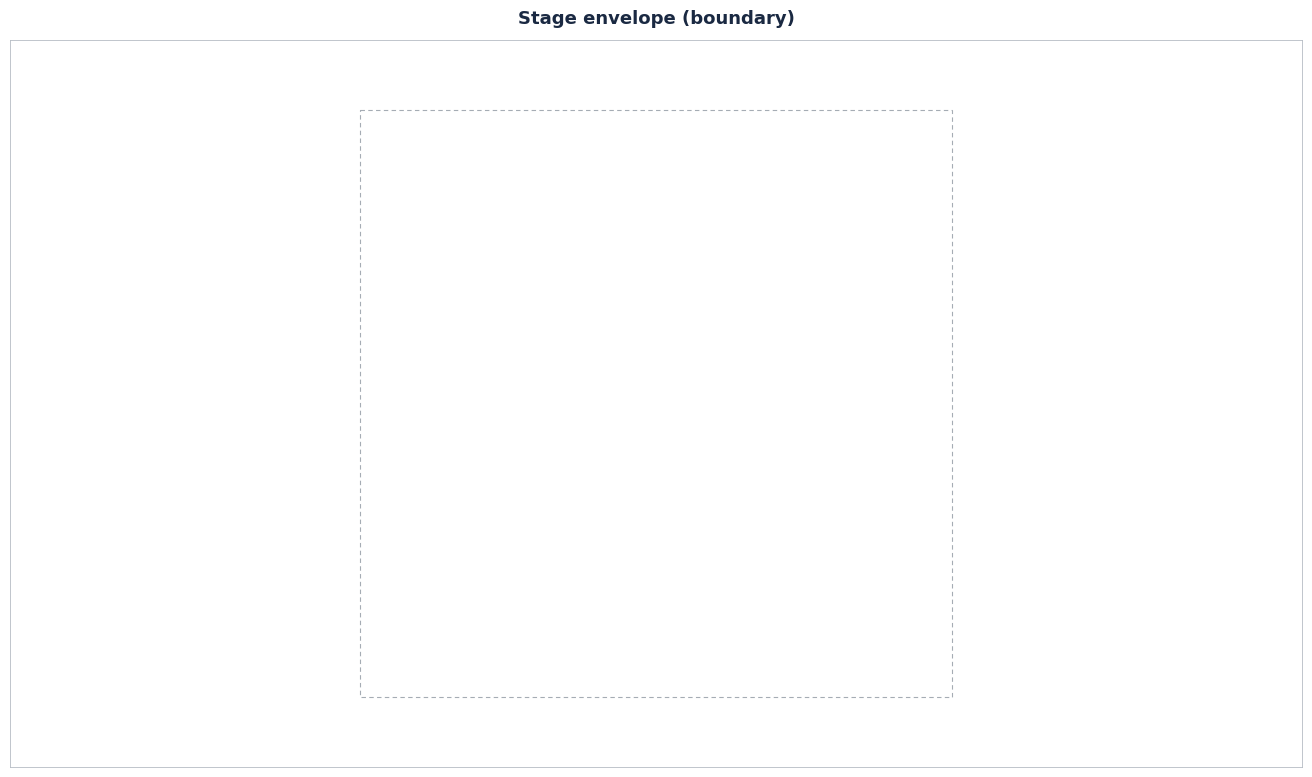

In [4]:
from workflow import prepare_template, plot_stage_envelope

prepare_template(ctx)
plot_stage_envelope(ctx)

### Step 2b — Define positions

Reads the scan field you drew — it defines which tiles the overview acquires.

**Before running:** draw the scan field in Navigator Expert.

[step 2b] Synthesized 9 tiles from geometries (tile size 1160.0 um)
[step 2b] Scan field: 1 group(s), 9 tile(s)
  Group 0: Overview  1x9  tile=1160.0 um
[step 2b] Saved E:\smart\v3-test_076rgj\initialization\logs\overview_field.png


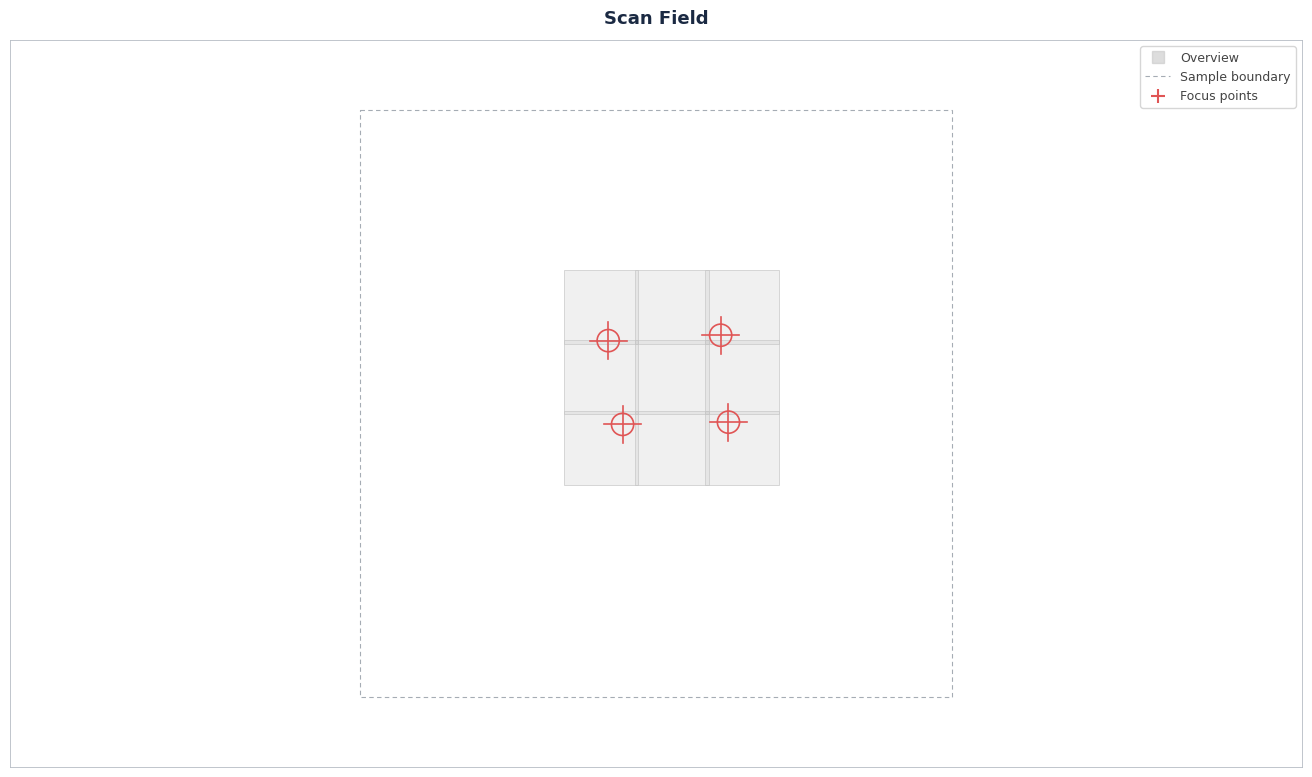

In [7]:
from workflow import read_scan_field, plot_scan_field

read_scan_field(ctx)
plot_scan_field(ctx)

### Step 2c — Define focus map

Runs autofocus at each focus marker and fits a z-wide surface across the scan field.

**Before running:** place focus markers on the scan field in Navigator Expert.

[step 2c] Focus positions (4):
  1. x=31036.4  y=18218.6 um
  2. x=32920.6  y=19495.9 um
  3. x=31261.3  y=19530.9 um
  4. x=32798.3  y=18133.5 um

[1/4] x=31036  y=18219  z-wide=5471.77 um

[2/4] x=32921  y=19496  z-wide=5464.77 um

[3/4] x=31261  y=19531  z-wide=5468.77 um

[4/4] x=32798  y=18134  z-wide=5467.77 um

[step 2c] Focus model: spline (4 points)
  Z range:      7.00 um
  Smoothing:    0.1
  Max residual: 0.007 um
[step 2c] Saved E:\smart\v3-test_076rgj\initialization\logs\focus_map.png


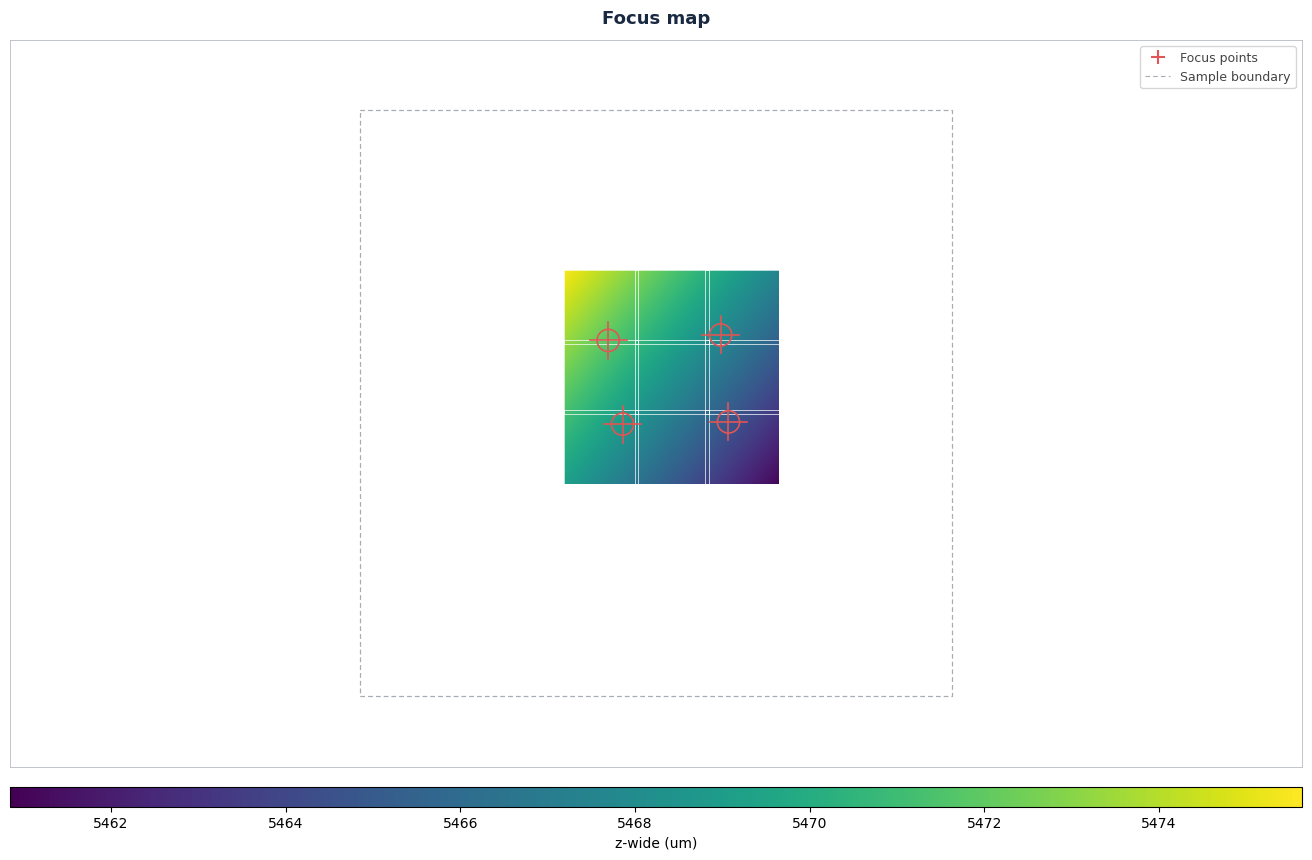

In [8]:
from workflow import build_focus_map

focus_map = build_focus_map(ctx)
focus_map.plot(ctx)

## Step 3 — Object Detection

Acquires every tile in snake order, segments each with cellpose, and writes the per-tile results to disk. Each tile is shown inline.

get_jobs: attempt 1/3 timed out


[job] 'Overview' selected (slot 1)
[step 3] 9 tiles in snake order
[1/9] Group 0, Position 0  x=30929 y=17692 z=5473.04  ok
[2/9] Group 0, Position 1  x=30929 y=18794 z=5470.95  ok
[3/9] Group 0, Position 2  x=30929 y=19896 z=5468.86  ok
[4/9] Group 0, Position 3  x=32031 y=17692 z=5470.44  ok


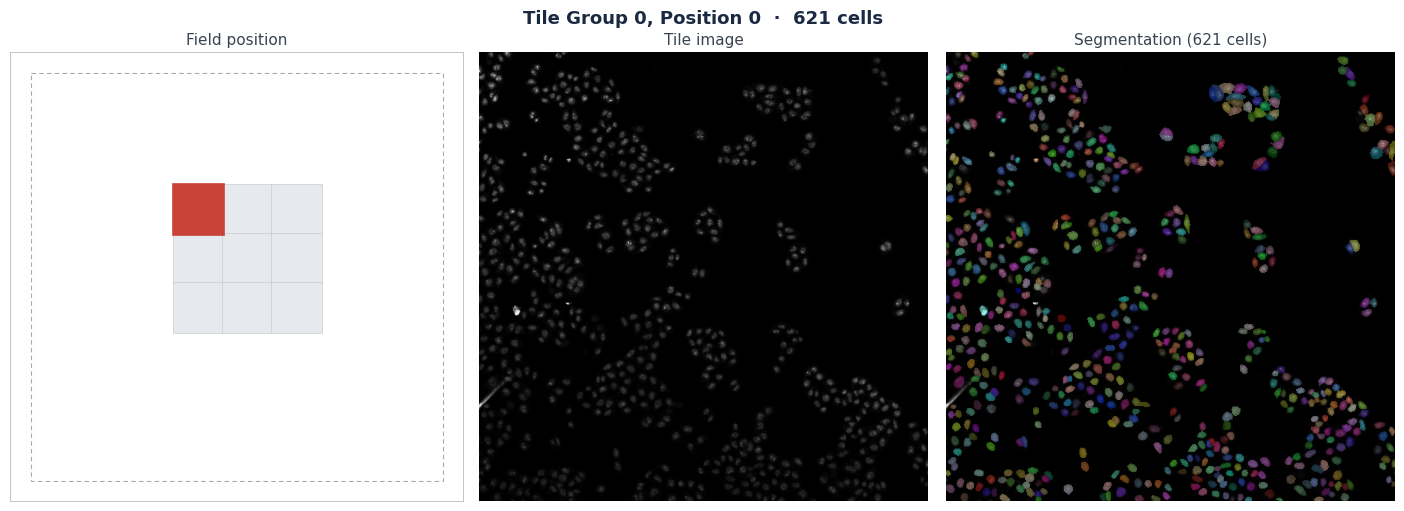

[5/9] Group 0, Position 4  x=32031 y=18794 z=5468.31  ok
[6/9] Group 0, Position 5  x=32031 y=19896 z=5466.18  ok
[7/9] Group 0, Position 6  x=33133 y=17692 z=5467.82  ok


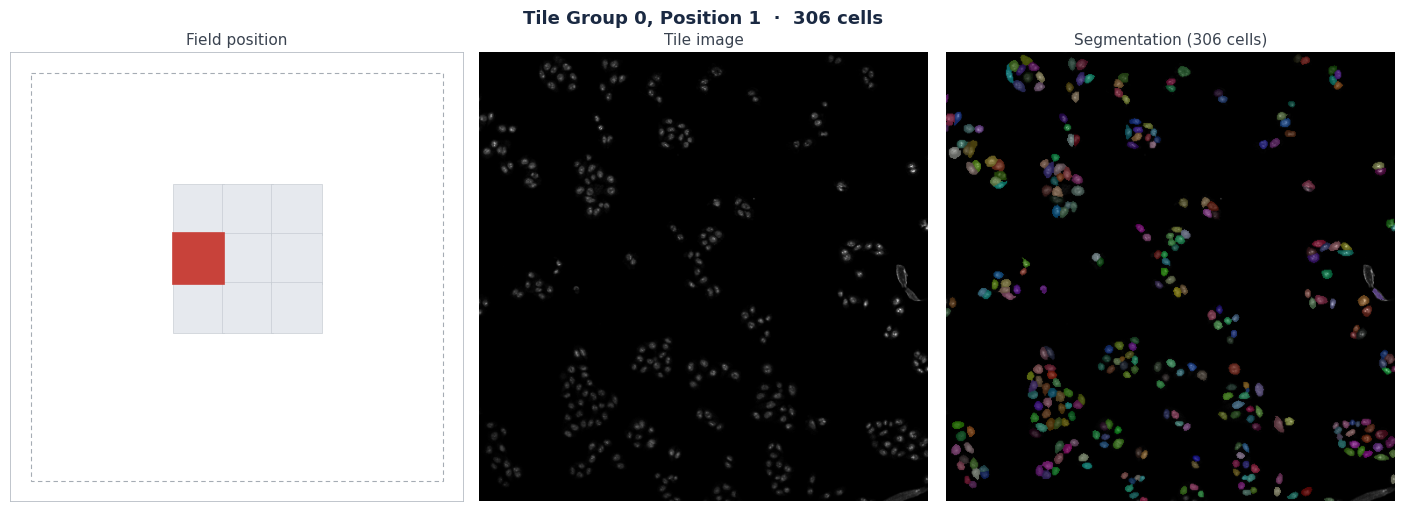

[8/9] Group 0, Position 7  x=33133 y=18794 z=5465.65  ok


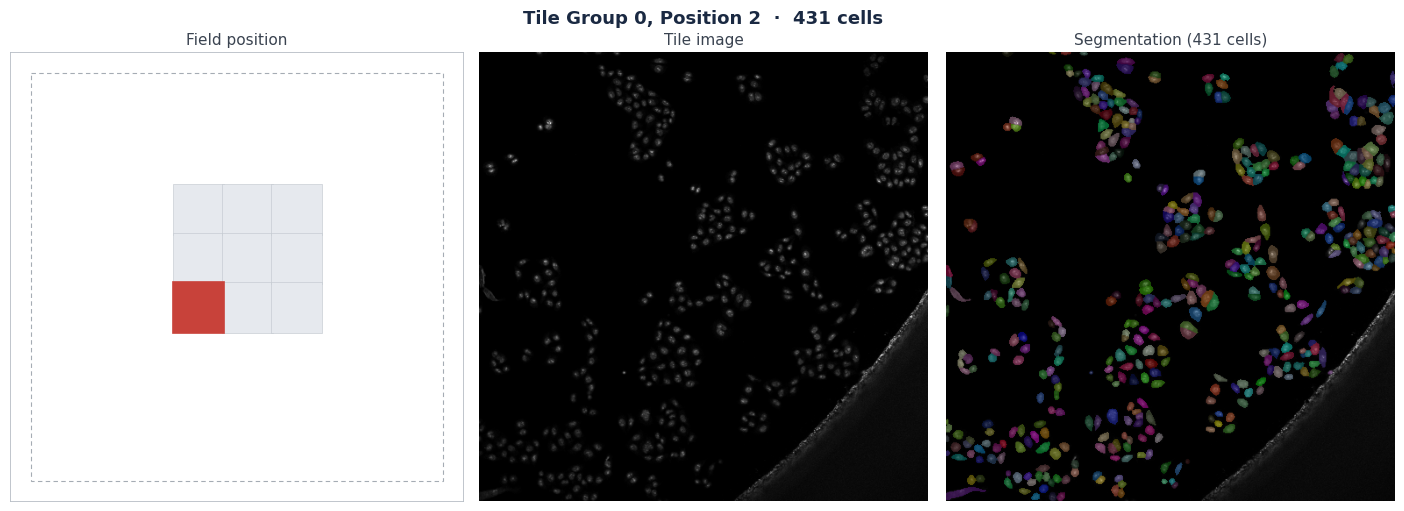

[9/9] Group 0, Position 8  x=33133 y=19896 z=5463.48  ok


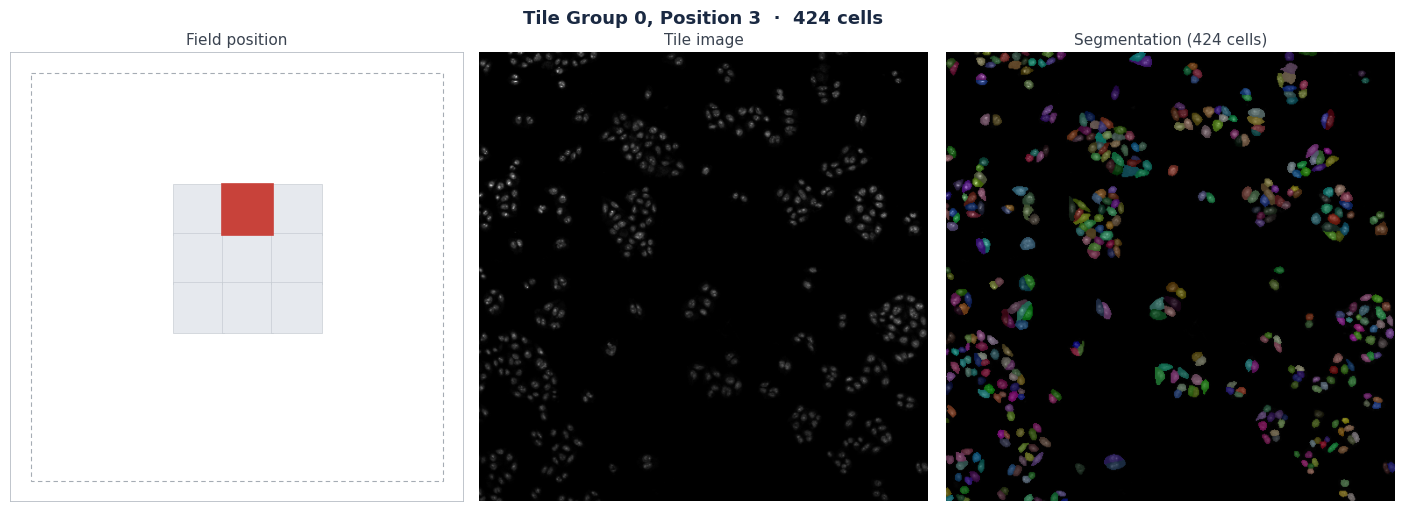

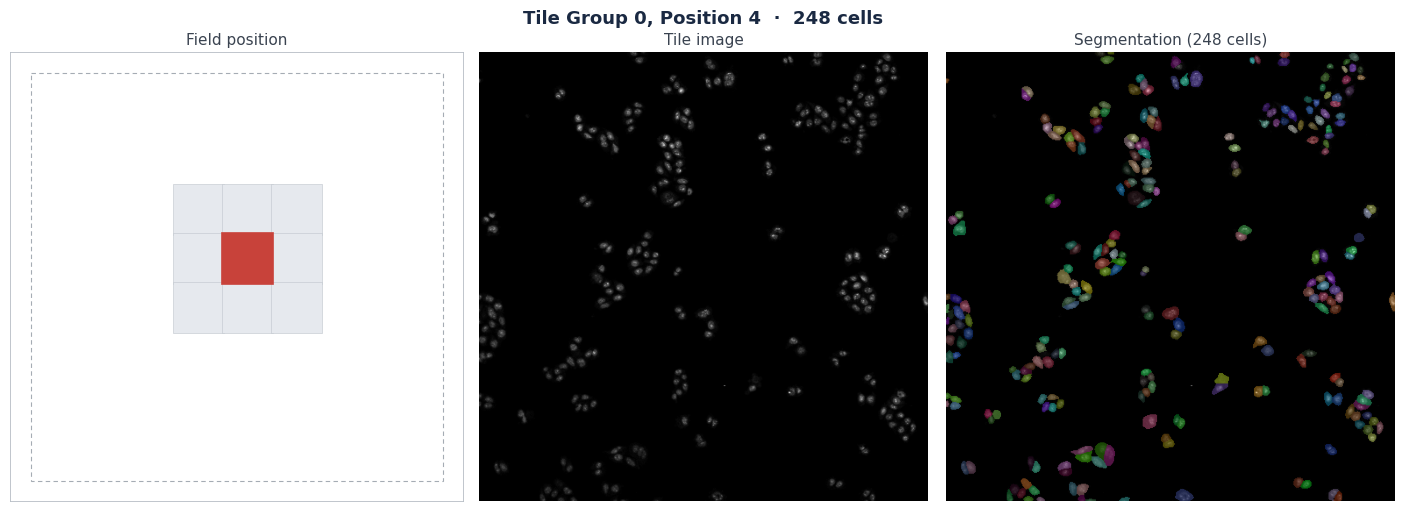

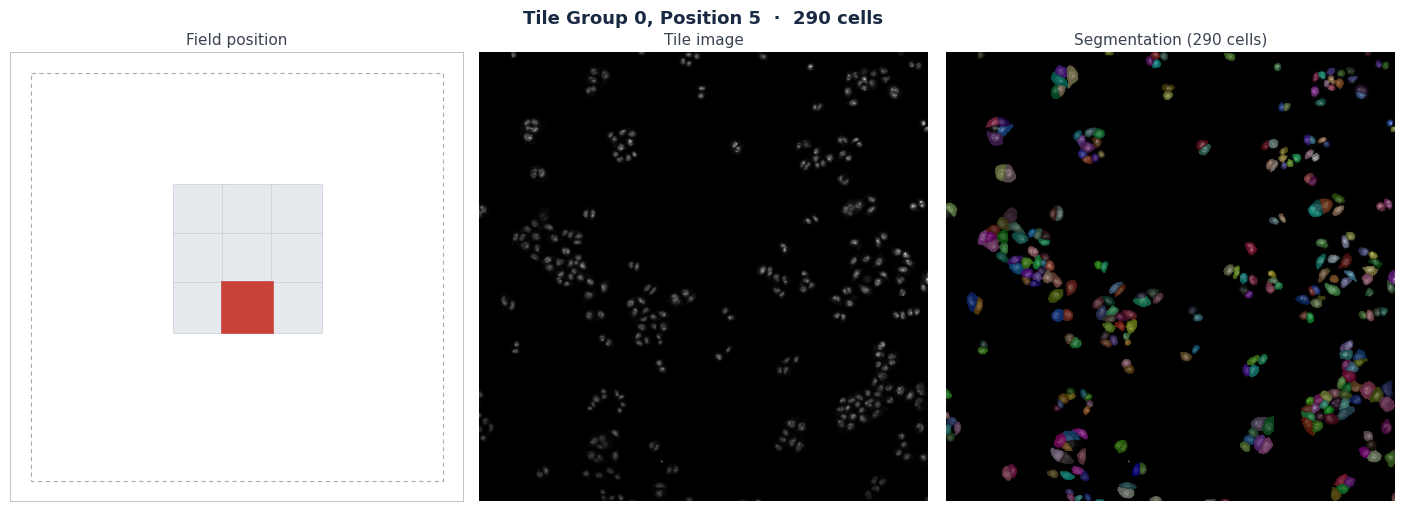

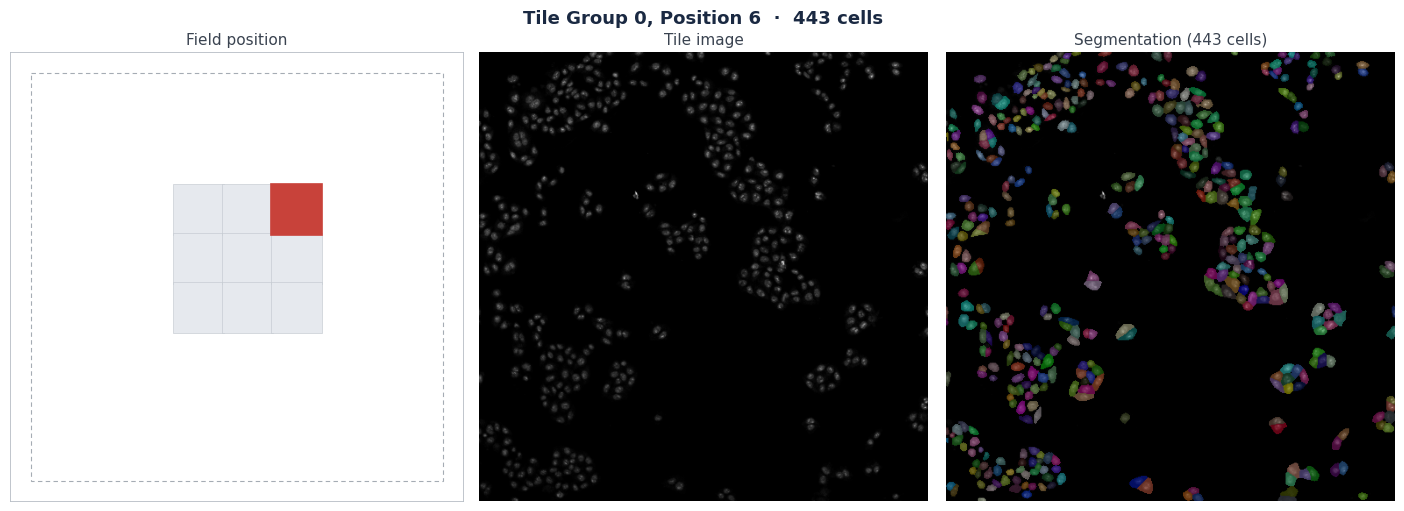

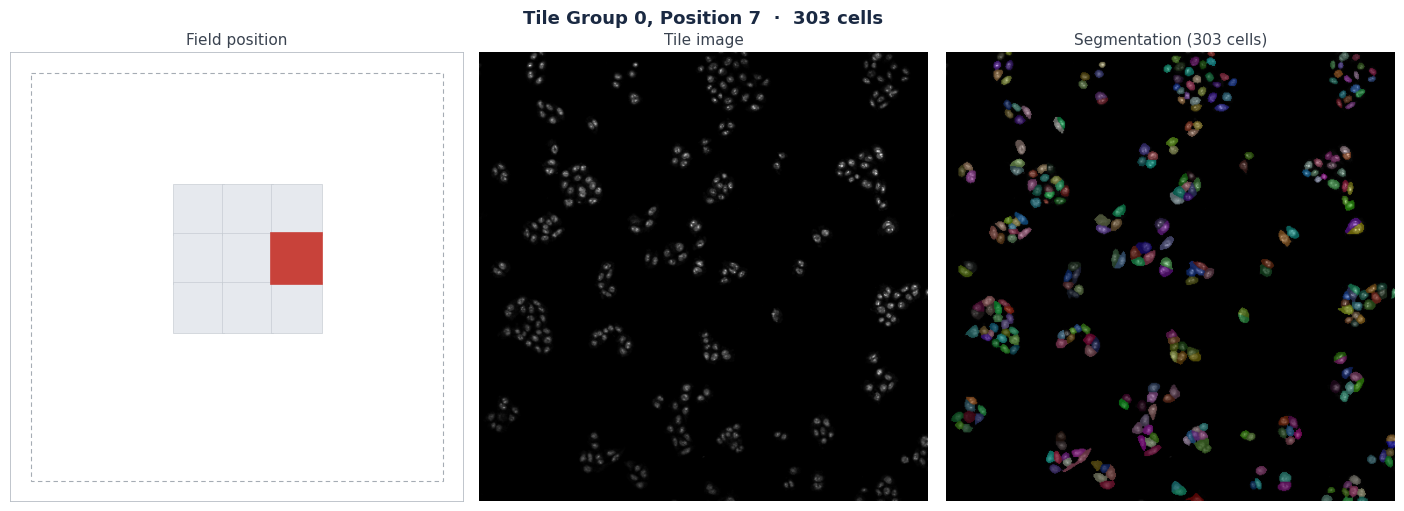

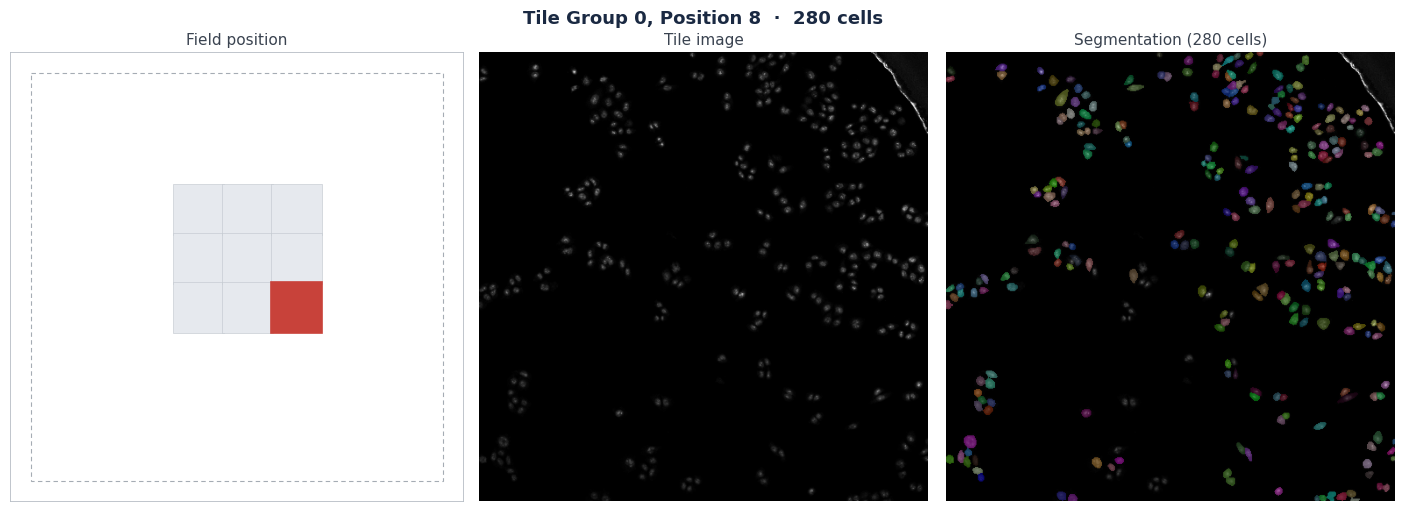


[step 3] Drain complete: 9 result(s), 0 engine failure(s), 0 tile acquire failure(s), 0 npz save failure(s). 9 tile(s) persisted.
[step 3] Template restored.


In [9]:
from workflow import run_overview

overview = run_overview(ctx, focus_map)

## Step 4 — Target discovery

Loads the overview, applies area / intensity thresholds, and picks target cells — shown as a scatter plus example crops.

Re-run with different `area_threshold`, `intensity_threshold`, `n_per_tile`, or `border_margin_px` to iterate without re-acquiring the overview.

[step 4] mode=threshold, total=3346 (1718 near-border excluded), qualifying=279, selected_pre_dedup=18, final=18 (area_threshold=88.0 auto, intensity_threshold=24.0 auto, border_margin_px=64)


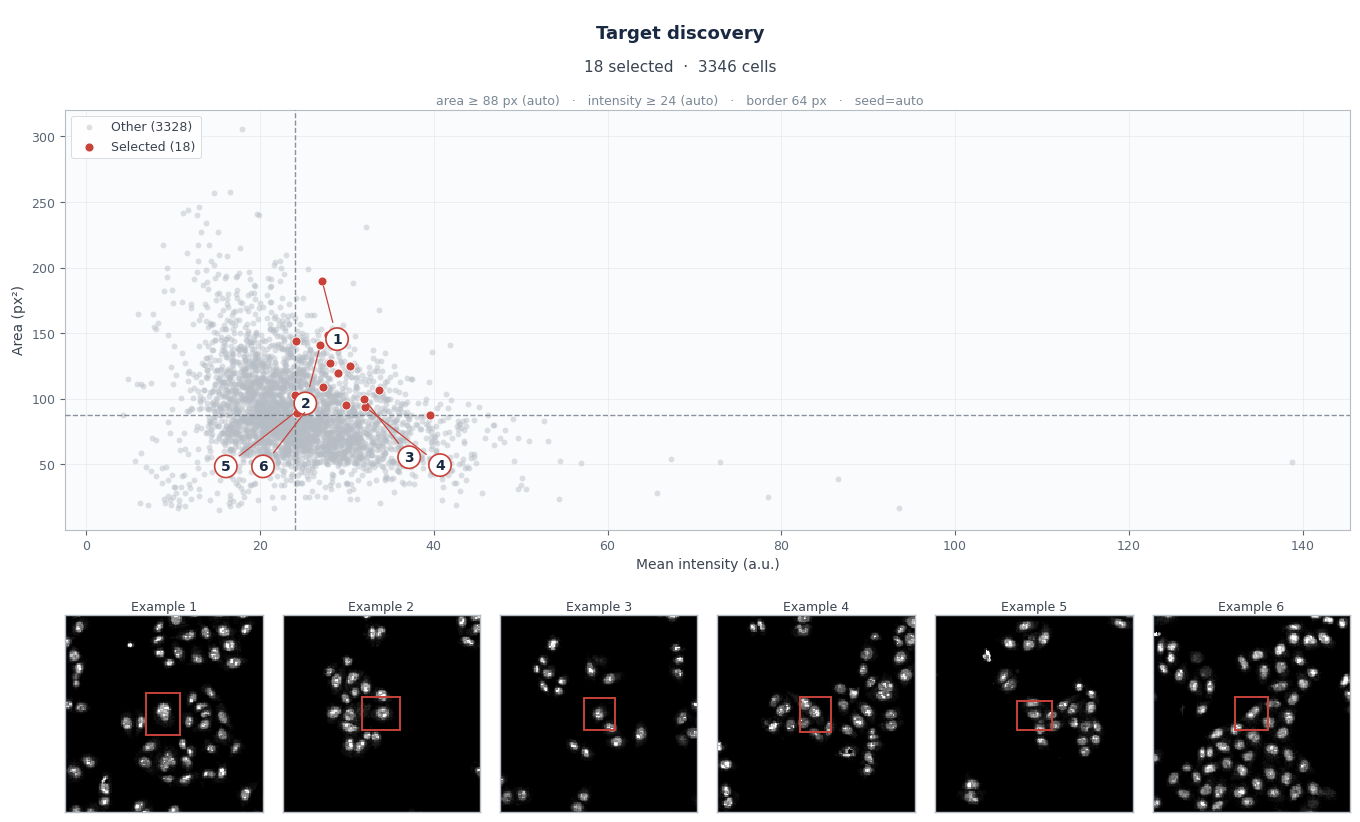

In [10]:
from workflow.selection import select_targets, load_overview_result
from workflow.visualize import display_selection

_analysis_dir = ctx.run.layout.analysis_dir("overview-scan")
overview = load_overview_result(_analysis_dir)   # kernel-restart safe

# Auto thresholds by default; uncomment to override. border_margin_px=64
# excludes cells whose bbox is within 64 px of any tile edge -- they have
# truncated stats and produce unreliable picks. Set to 0 to disable.
picks, selection = select_targets(
    overview,
    ctx.limits_context(),
    n_per_tile=2,
    border_margin_px=64,
    # area_threshold=200,
    # intensity_threshold=100,
    # seed=42,
)
display_selection(
    selection, _analysis_dir,
    logs_dir=ctx.run.layout.logs_dir("overview-scan"),
)

## Step 5 — Target acquisition

Switches to the target job and re-acquires each picked cell at high magnification; a failed pick does not stop the rest.

get_jobs: attempt 1/3 timed out
get_jobs: attempt 2/3 timed out
get_jobs: attempt 3/3 timed out
get_jobs: all 3 attempts failed
get_jobs: attempt 1/3 timed out
get_jobs: attempt 2/3 timed out
get_jobs: attempt 3/3 timed out
get_jobs: all 3 attempts failed
Job selection timeout after 5.0s for 'HiRes'
get_jobs: attempt 1/3 timed out


[job] 'HiRes' selected (slot 2)
[step 5] 18 picks to acquire at slot 2
[1/18] Group 0, Position 0, label 458  src=(30567, 17838)  ok  tz=5469.3


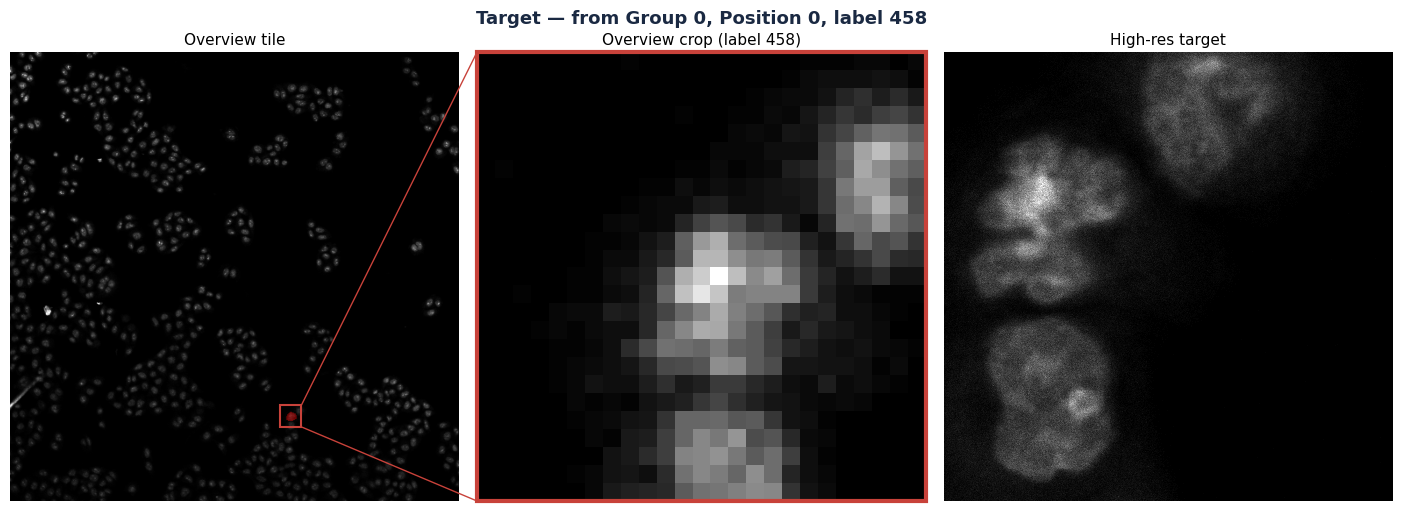

[2/18] Group 0, Position 2, label 342  src=(30569, 19745)

get_xy: attempt 1/3 receipt failed


  ok  tz=5465.2


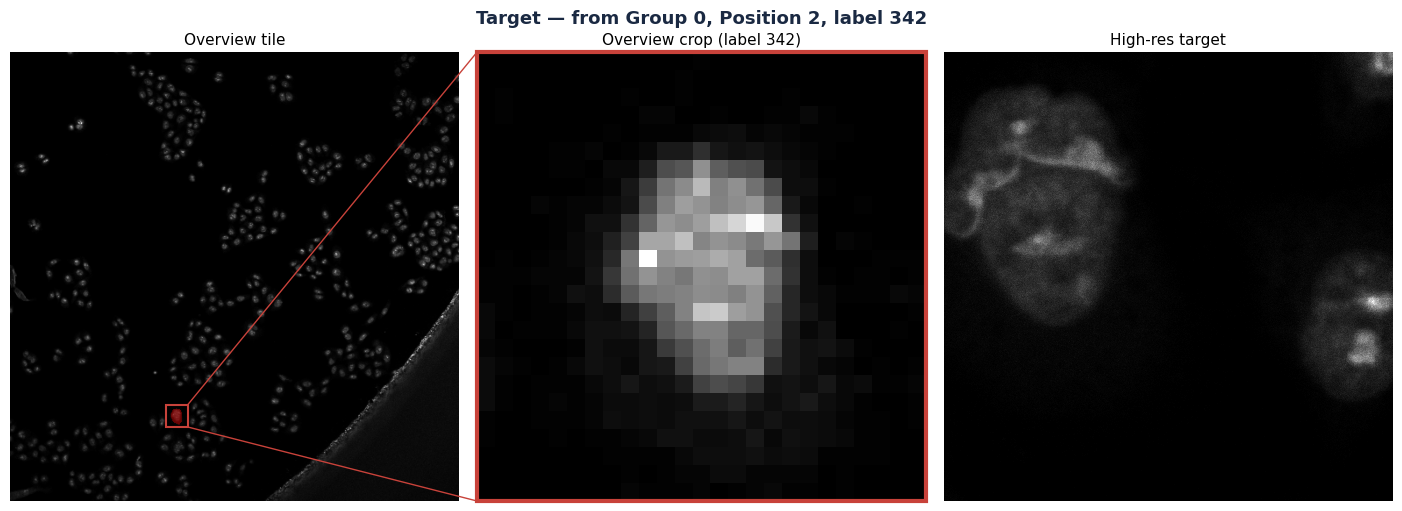

[3/18] Group 0, Position 1, label 170  src=(30691, 18959)  ok  tz=5467.2


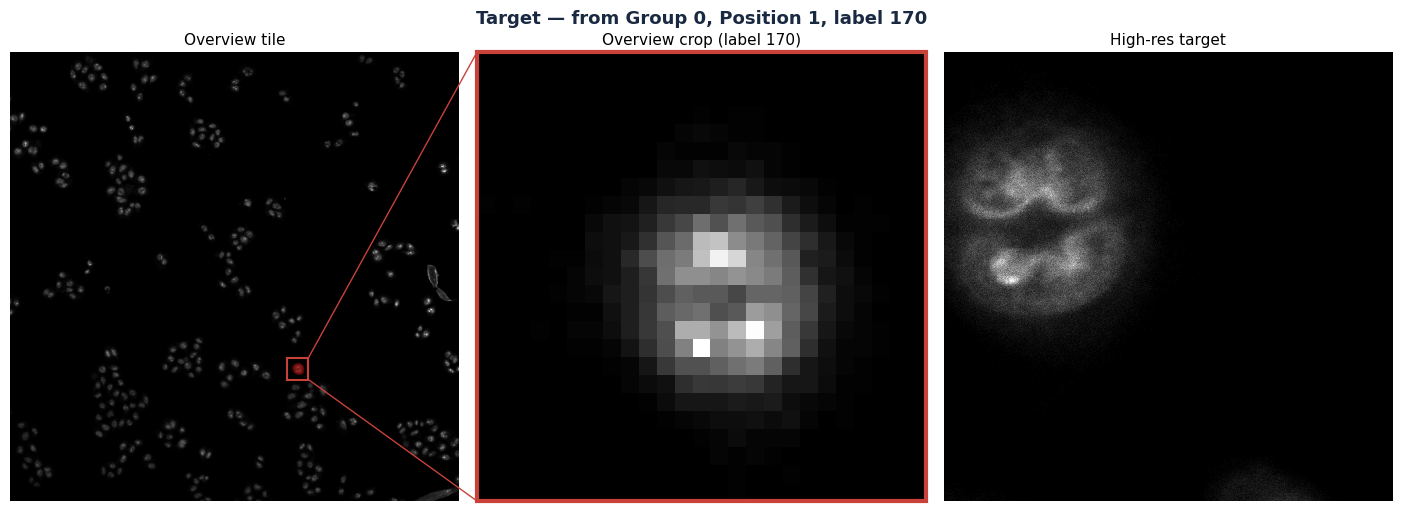

[4/18] Group 0, Position 0, label 353  src=(30730, 17501)  ok  tz=5469.3


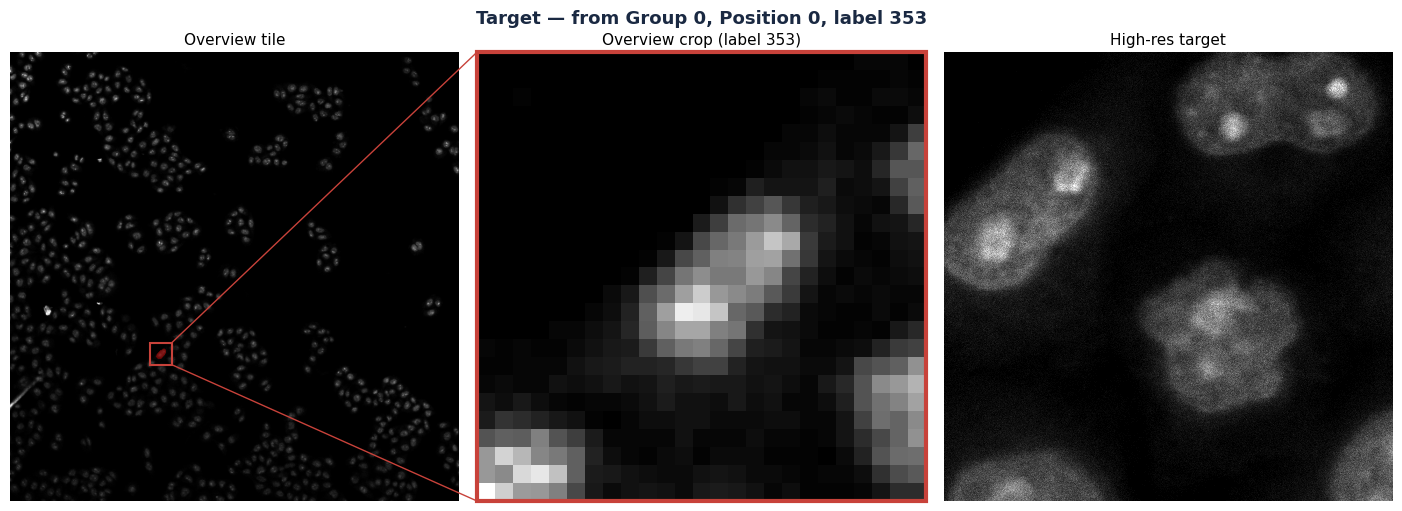

[5/18] Group 0, Position 2, label 280  src=(30738, 19839)  ok  tz=5465.2


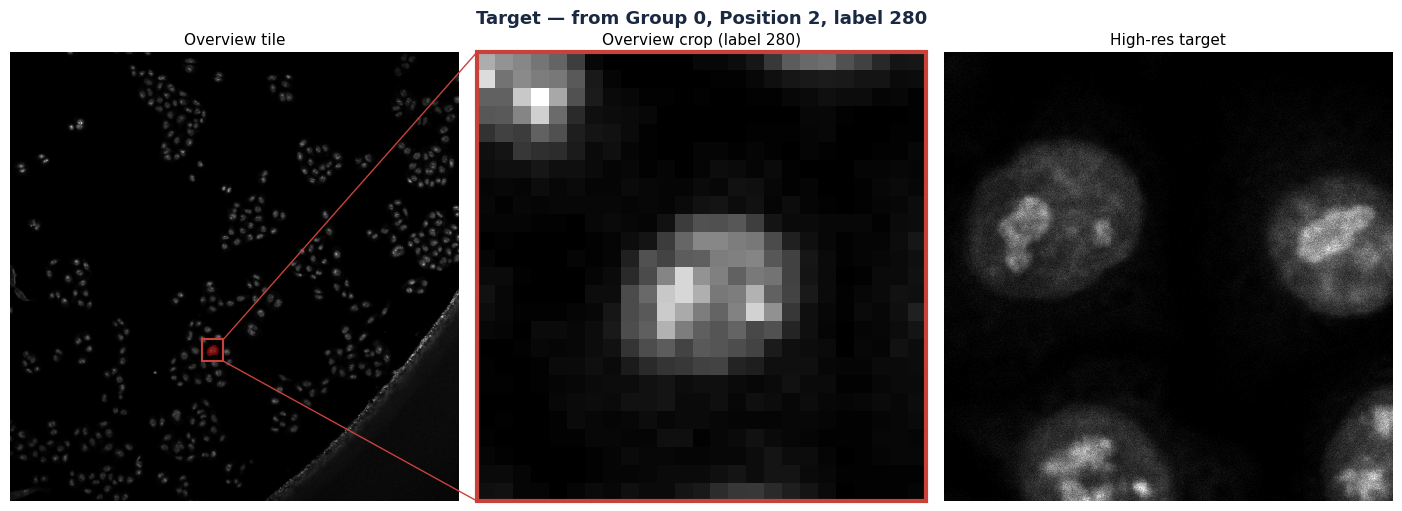

[6/18] Group 0, Position 1, label 80  src=(31152, 18553)  ok  tz=5467.2


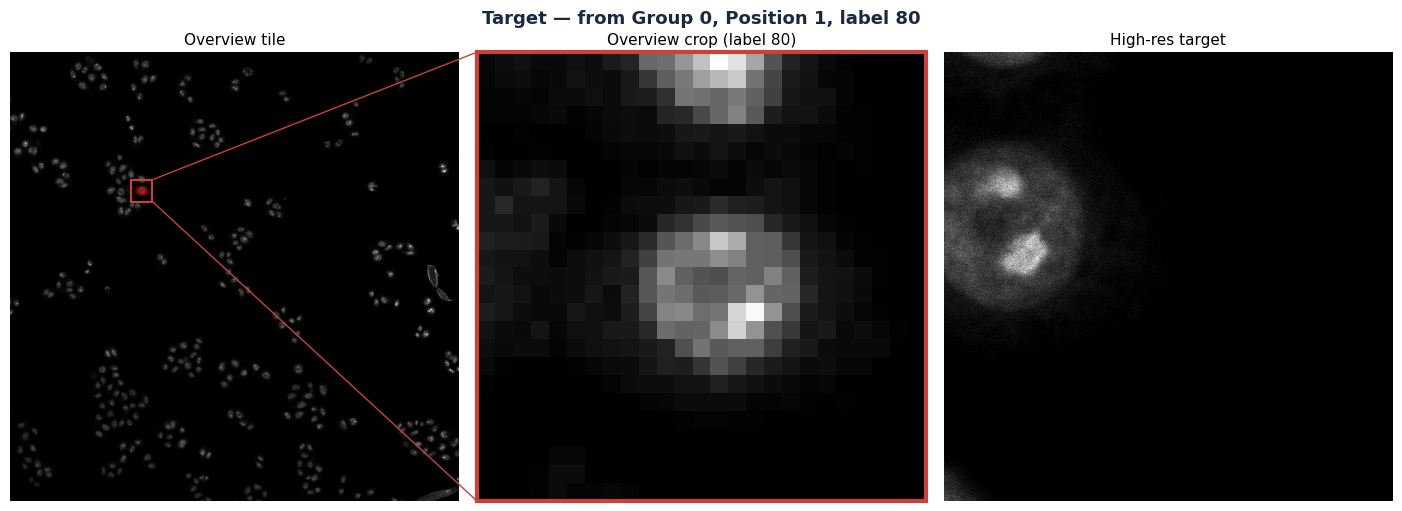

[7/18] Group 0, Position 5, label 121  src=(32044, 20065)  ok  tz=5462.5


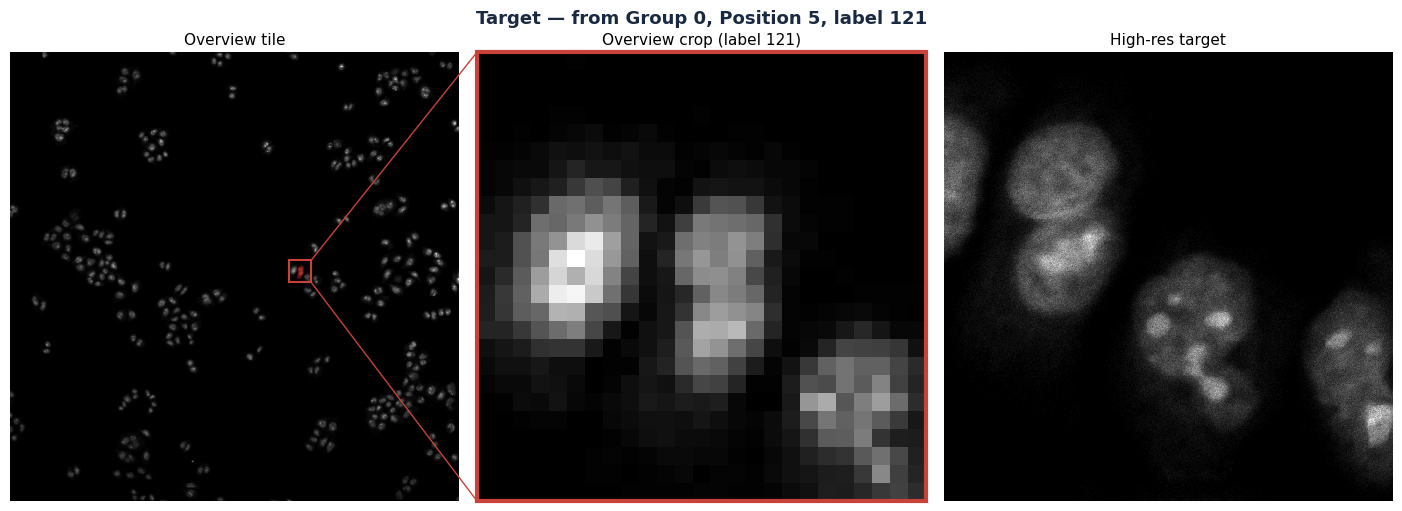

[8/18] Group 0, Position 3, label 138  src=(32241, 17773)  ok  tz=5466.7


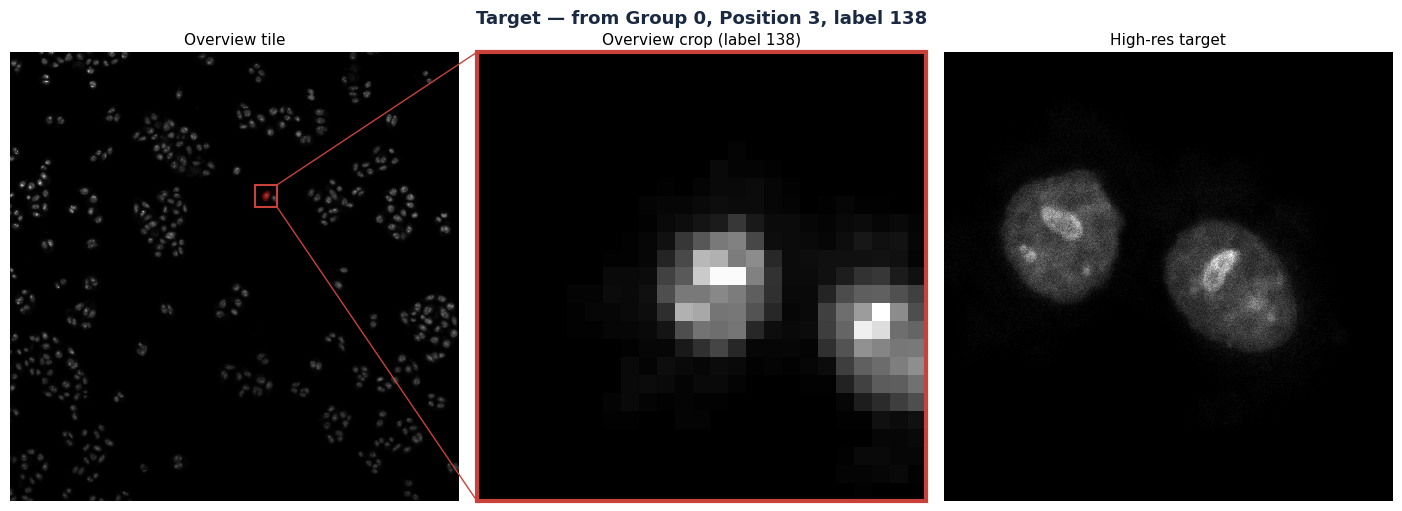

[9/18] Group 0, Position 3, label 116  src=(32307, 17698)  ok  tz=5466.7


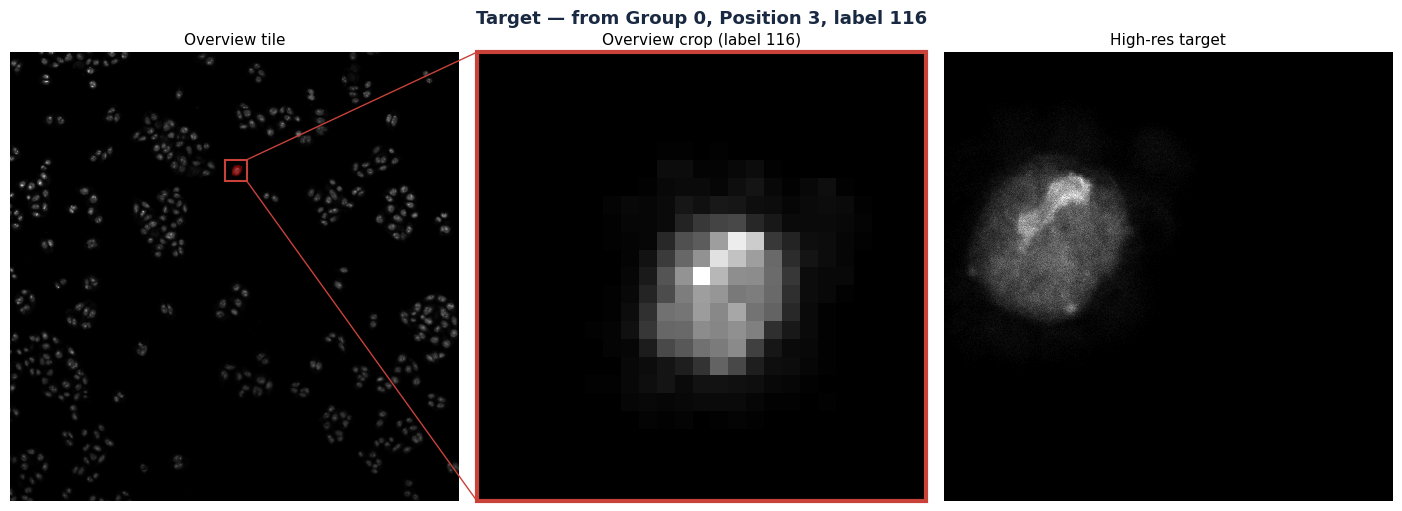

[10/18] Group 0, Position 5, label 47  src=(32379, 19704)  ok  tz=5462.5


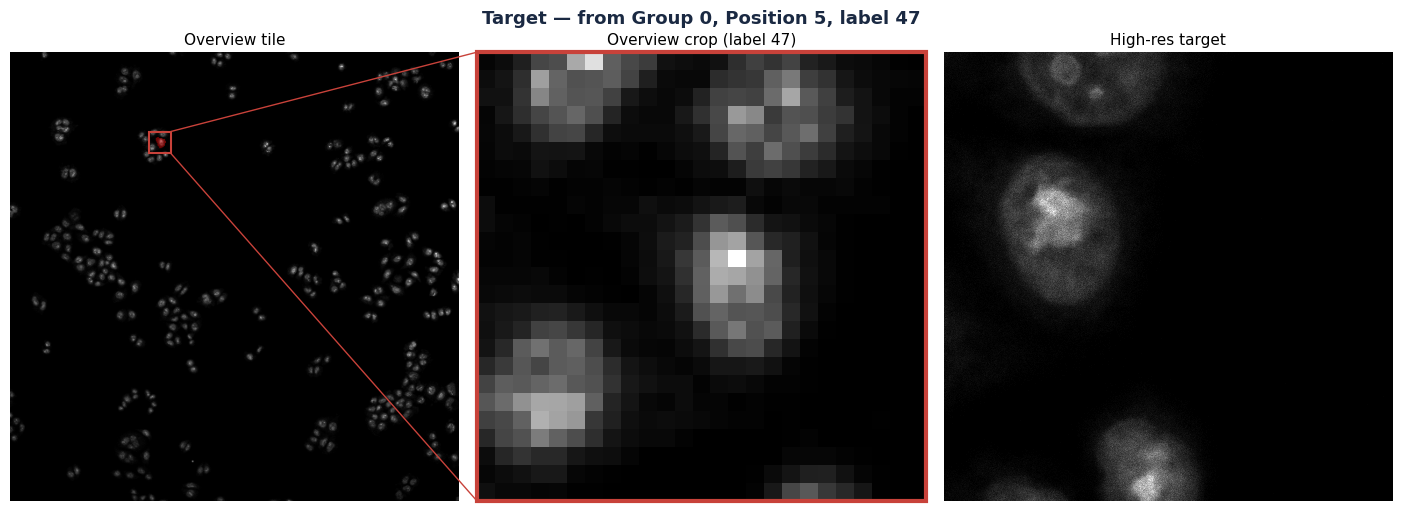

[11/18] Group 0, Position 4, label 47  src=(32440, 18468)  ok  tz=5464.6


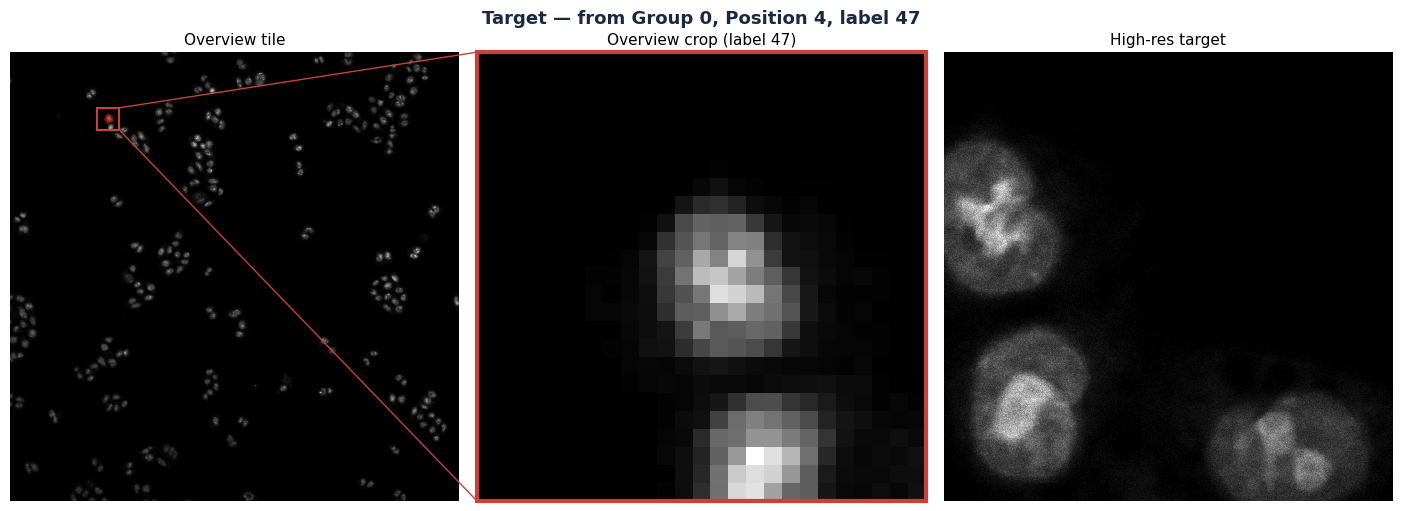

[12/18] Group 0, Position 4, label 45  src=(32449, 19109)  ok  tz=5464.6


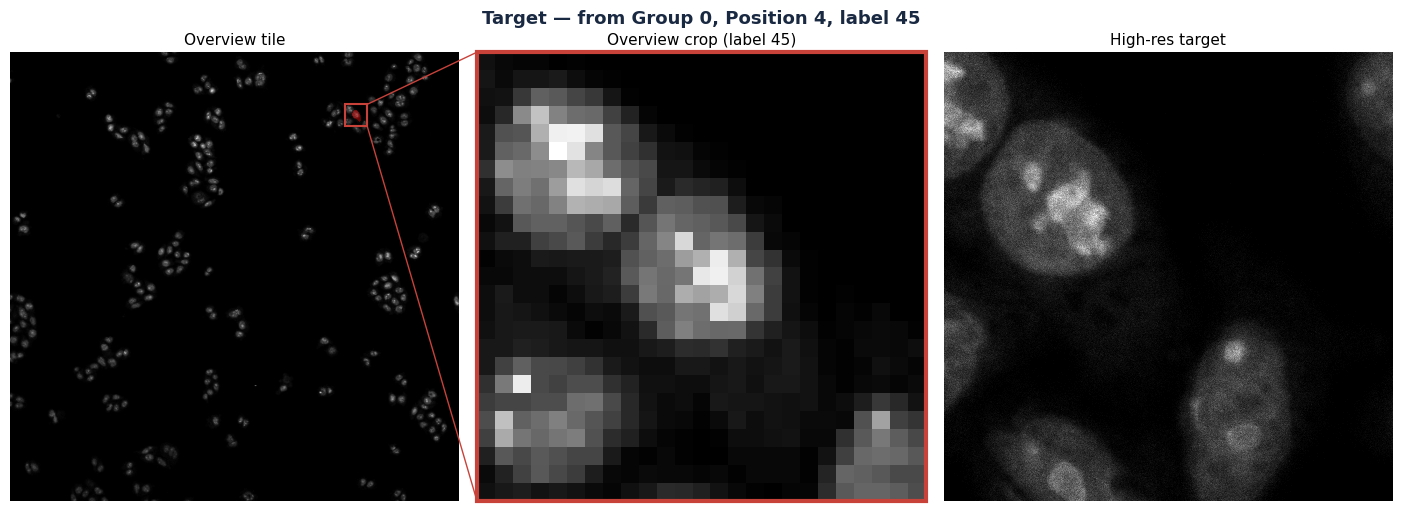

[13/18] Group 0, Position 7, label 153  src=(33147, 18779)  ok  tz=5462.0


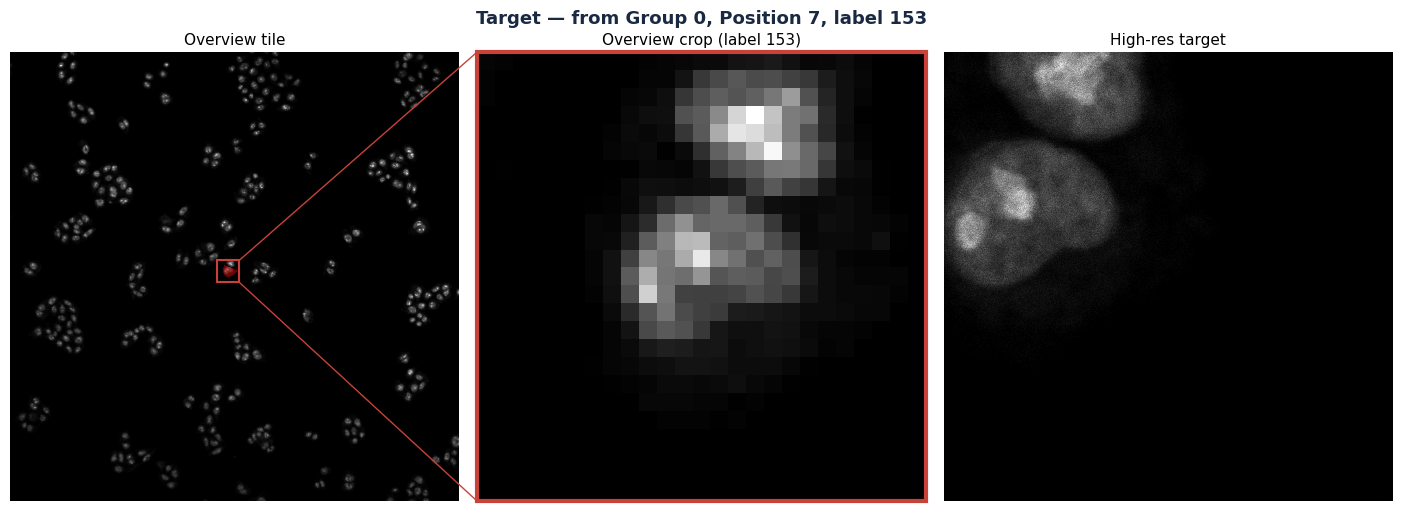

[14/18] Group 0, Position 6, label 218  src=(33248, 17595)  ok  tz=5464.1


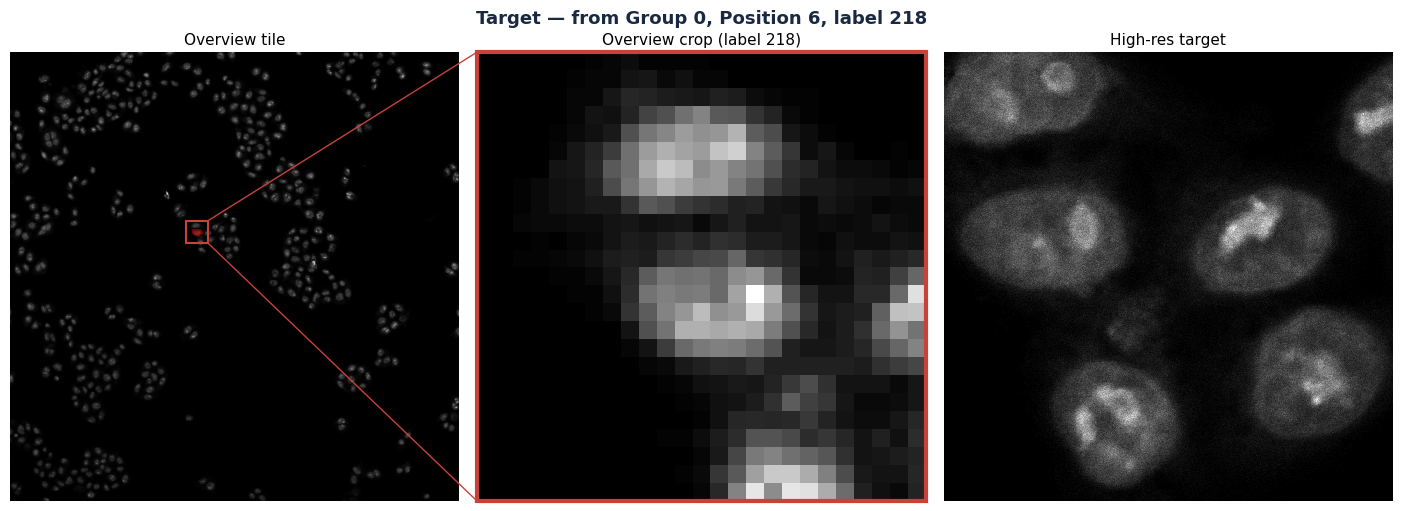

[15/18] Group 0, Position 7, label 126  src=(33258, 18777)  ok  tz=5462.0


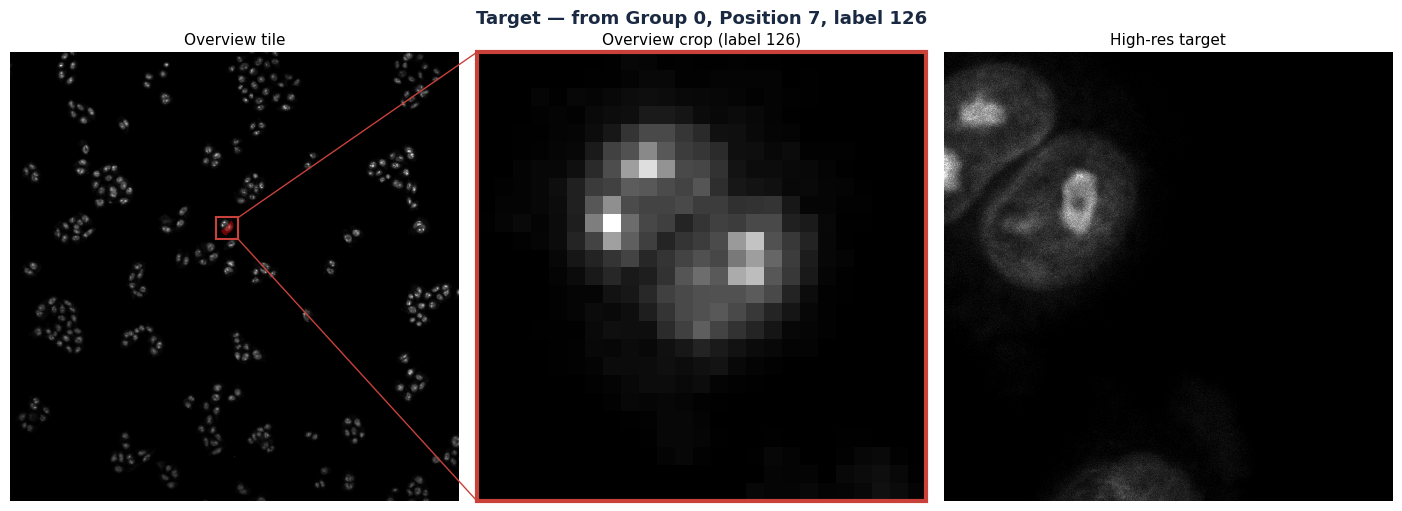

[16/18] Group 0, Position 8, label 123  src=(33353, 19620)  ok  tz=5459.8


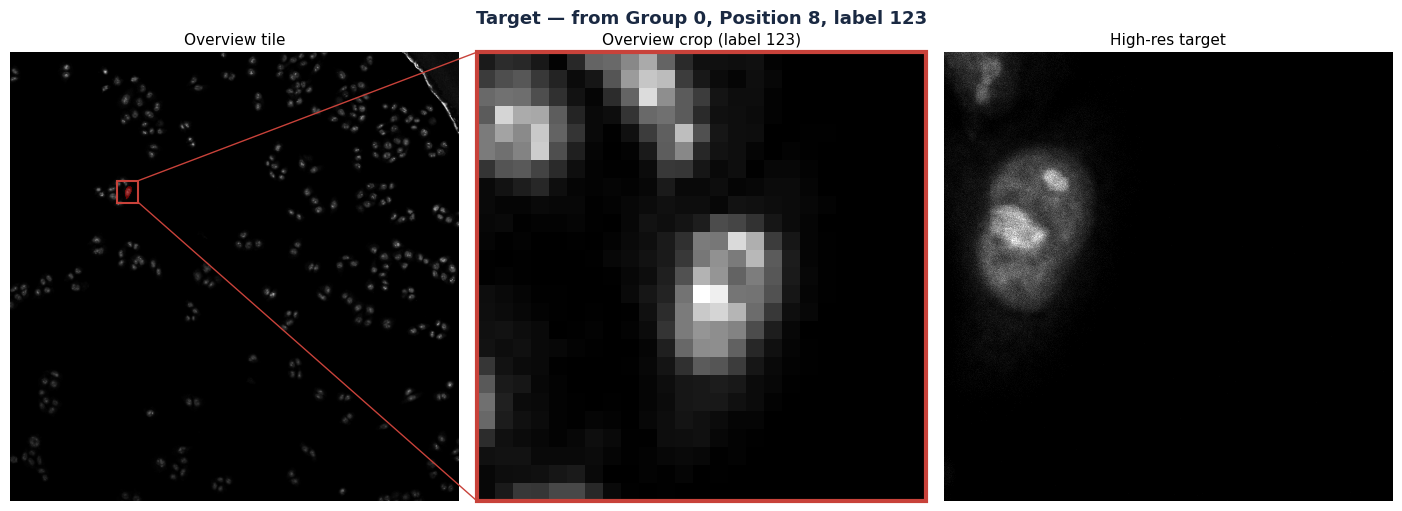

[17/18] Group 0, Position 8, label 124  src=(33354, 20085)  ok  tz=5459.8


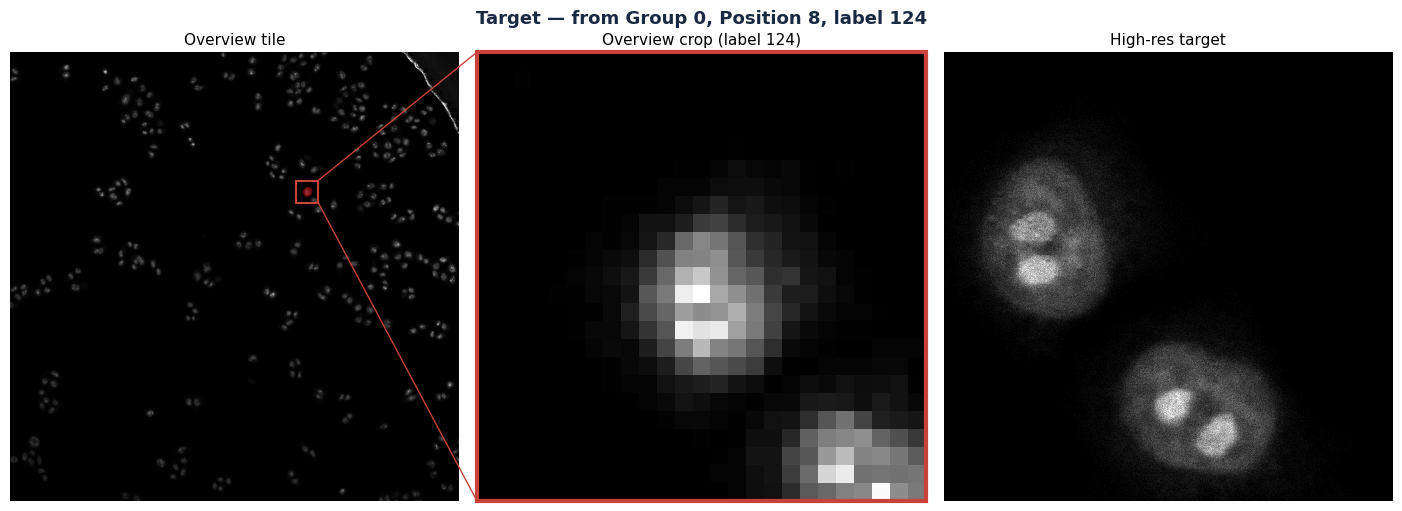

[18/18] Group 0, Position 6, label 112  src=(33520, 18013)  ok  tz=5464.1


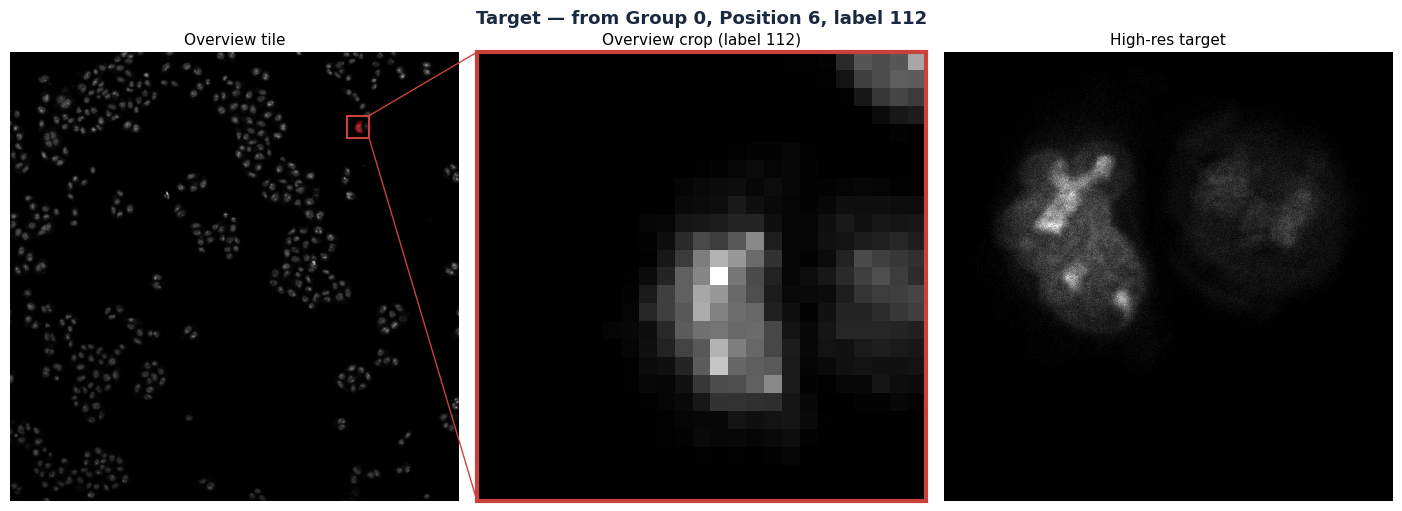


[step 5] Done: 18/18 targets acquired
[step 5] Template restored.


In [11]:
from workflow import acquire_targets

records = acquire_targets(ctx, picks)


## Step 6 — Finish

Writes `run_summary.json`, plots the results, and shuts down the engine.

The Cleanup cell below is a safety backstop for interrupted runs — not part of the normal path.

In [ ]:
from workflow import write_summary, plot_results, finish
from workflow.selection import load_overview_result

# Reload from disk so the finish cell is consistent with selection above
# (restart-between-selection-and-finish is NOT supported -- picks,
# selection, and records must still be in-kernel here).
overview = load_overview_result(ctx.run.layout.analysis_dir("overview-scan"))
write_summary(ctx, focus_map, overview, picks, selection, records)
plot_results(ctx, focus_map, picks, records)
finish(ctx)

In [ ]:
# Cleanup -- safety backstop for interrupted runs. Shuts down the
# analysis engine. Does NOT disconnect the LAS X client; it persists
# until kernel restart. Always safe to run.
try:
    ctx.shutdown()
except NameError:
    pass
